# Phase 2: Choosing the RUL cap from training engines (05)

Issue #55. The training target is the remaining useful life (RUL). A training engine runs until it fails, so its RUL at cycle 1 can be 300 or more. But while an engine is healthy its sensors do not move, and an engine with 300 cycles left looks the same as one with 200 left. That part of the uncapped target cannot be learned, so models are usually trained on a **capped** target: flat at the cap while healthy, then falling linearly to 0.

Phase 1 used a cap of 125 because it is common in the literature, and the official test score for 125 was already known. This notebook replaces that with a rule that uses **training engines only**:

1. Build a one-number **health index** per cycle from the sensors.
2. Fit a **hinge** (flat, then rising) to each engine's index. The bend marks where degradation becomes visible, and the RUL at the bend is that engine's *onset RUL*.
3. **K** = 90th percentile of the onset RULs in the training fold.
4. Score each candidate cap on held-out engines using only cycles with **true RUL ≤ K**, and pick the lowest RMSE.

The heavy part (5 seeds × 3 folds × 4 caps × 3 models) runs in `scripts/choose_rul_cap.py`. This notebook draws the figures from its saved scores.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from rul.data.load import load_training
from rul.data.split import group_kfold_splits
from rul.data.target import HealthIndex, fit_hinge, hinge_onsets
from rul.evaluation.plots import save_figure

ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == "phase2" else Path.cwd()
METRICS = ROOT / "results" / "metrics"
train = load_training("FD001", data_dir=ROOT / "data/raw/CMAPSSData")
print(train["unit"].nunique(), "training engines,", len(train), "cycles")

100 training engines, 20631 cycles


## 1. The health index

Each retained sensor is z-scored with the training fold's mean and standard deviation, so all sensors are on the same scale. Some sensors rise as the engine wears (for example `s_2` and `s_4`, temperatures) and some fall (for example `s_7` and `s_12`), so each one is multiplied by the sign of its correlation with the cycles to failure. Averaging them gives one index that rises toward failure, with much less noise than any single sensor. All of this is fitted on training rows only, so a held-out engine never shapes its own index.

In [2]:
index = HealthIndex().fit(train)
health = index.transform(train)
print("kept sensors:", index.sensors_)
print("falling sensors (sign -1):", [s for s, v in index.sign_.items() if v < 0])

kept sensors: ['s_2', 's_3', 's_4', 's_6', 's_7', 's_8', 's_9', 's_11', 's_12', 's_13', 's_14', 's_15', 's_17', 's_20', 's_21']
falling sensors (sign -1): ['s_7', 's_12', 's_20', 's_21']


## 2. Hinge fits: where does degradation start?

For each engine we try every cycle τ as the bend, fit `level` before τ and `level + slope·(t − τ)` after it by least squares, and keep the τ with the smallest error. Training engines end at failure, so the onset RUL is `last cycle − τ`. Below are four engines: the shortest, the longest and two in between.

PosixPath('/Users/yashiagrawal/Desktop/cmapss-rul-hybrid/results/figures/fd001_rul_cap_hinge_fits.png')

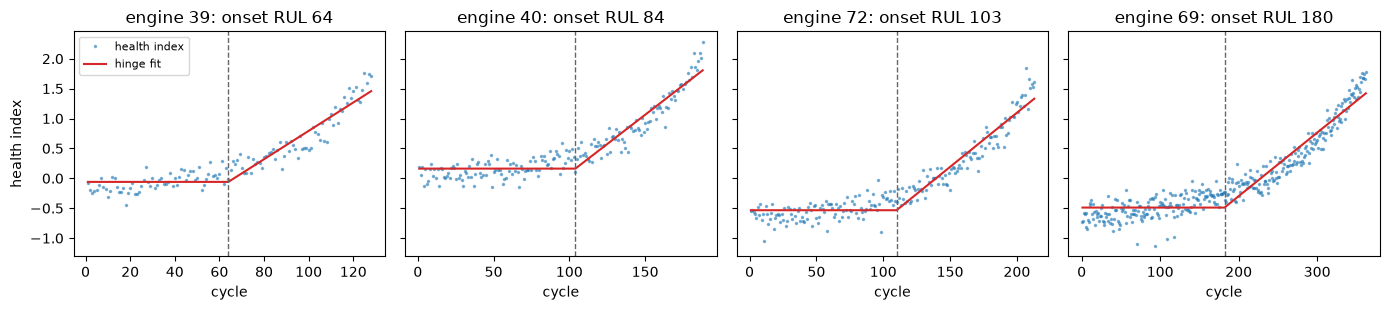

In [3]:
onsets = hinge_onsets(train, health)
life = onsets["last_cycle"].sort_values()
examples = [life.index[0], life.index[len(life) // 3], life.index[2 * len(life) // 3], life.index[-1]]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for ax, unit in zip(axes, examples):
    rows = train["unit"] == unit
    t, h = train.loc[rows, "cycle"].to_numpy(), health[rows].to_numpy()
    fit = onsets.loc[unit]
    ax.plot(t, h, ".", ms=3, alpha=0.5, label="health index")
    ax.plot(t, fit["level"] + fit["slope"] * np.maximum(t - fit["onset_cycle"], 0), "C3", label="hinge fit")
    ax.axvline(fit["onset_cycle"], color="0.4", ls="--", lw=1)
    ax.set_title(f"engine {unit}: onset RUL {fit['onset_rul']:.0f}")
    ax.set_xlabel("cycle")
axes[0].set_ylabel("health index")
axes[0].legend(loc="upper left", fontsize=8)
fig.tight_layout()
save_figure(fig, "fd001_rul_cap_hinge_fits")

## 3. Onset distribution and K

K is computed **inside each training fold**, so the held-out engines never influence it. With the seed-42 folds the 90th percentile lands at about 134, 132 and 123, matching the prototype quoted in the issue (134, 132, 124).

K per fold (seed 42): [134.  131.8 123.2]
count    100.0
mean      94.7
std       24.4
min       59.0
25%       75.8
50%       91.5
75%      107.0
max      180.0
Name: onset_rul, dtype: float64


PosixPath('/Users/yashiagrawal/Desktop/cmapss-rul-hybrid/results/figures/fd001_rul_cap_onset_distribution.png')

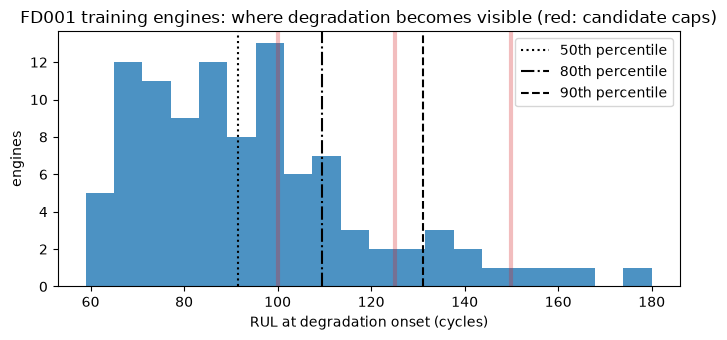

In [4]:
fold_k = []
for fold, (idx, _) in enumerate(group_kfold_splits(train, 3, 42)):
    part = train.iloc[idx]
    o = hinge_onsets(part, HealthIndex().fit(part).transform(part))["onset_rul"]
    fold_k.append(np.percentile(o, 90))
print("K per fold (seed 42):", np.round(fold_k, 1))
print(onsets["onset_rul"].describe().round(1))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(onsets["onset_rul"], bins=20, color="C0", alpha=0.8)
for q, ls in [(50, ":"), (80, "-."), (90, "--")]:
    ax.axvline(np.percentile(onsets["onset_rul"], q), color="k", ls=ls, label=f"{q}th percentile")
for cap in (100, 125, 150):
    ax.axvline(cap, color="C3", alpha=0.3, lw=3)
ax.set_xlabel("RUL at degradation onset (cycles)")
ax.set_ylabel("engines")
ax.set_title("FD001 training engines: where degradation becomes visible (red: candidate caps)")
ax.legend()
fig.tight_layout()
save_figure(fig, "fd001_rul_cap_onset_distribution")

## 4. Score by cap

Each panel shows the mean over 5 seeds of the fold-mean RMSE, with the spread across seeds as error bars. Left: every held-out cycle. Right: the selection metric, i.e. cycles with true RUL ≤ K (K at the 90th percentile).

rmse_all       rmse_selected      
                       mean   std          mean   std
model         cap                                    
elastic_net   100     58.33  0.26         17.94  0.14
              125     49.34  0.32         18.68  0.18
              150     44.22  0.37         22.87  0.31
              none    41.00  0.62         32.69  0.73
random_forest 100     58.33  0.21         15.62  0.36
              125     47.94  0.09         14.97  0.30
              150     41.22  0.24         17.42  0.36
              none    36.73  0.55         23.57  0.70
xgboost       100     58.17  0.32         15.57  0.38
              125     47.94  0.28         15.54  0.38
              150     41.68  0.52         18.19  0.26
              none    38.86  0.99         24.97  0.89

PosixPath('/Users/yashiagrawal/Desktop/cmapss-rul-hybrid/results/figures/fd001_rul_cap_score_by_cap.png')

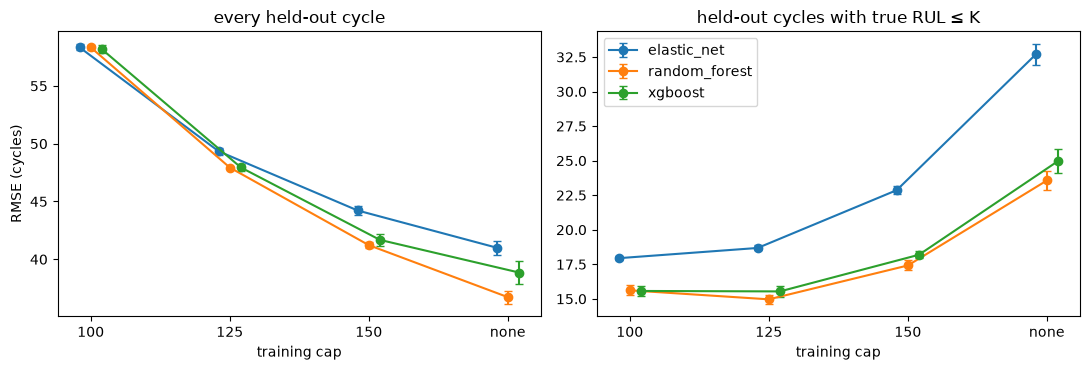

In [5]:
scores = pd.read_csv(METRICS / "fd001_rul_cap_scores.csv", dtype={"cap": str})
choices = pd.read_csv(METRICS / "fd001_rul_cap_choices.csv", dtype={"chosen_cap": str})
summary = json.loads((METRICS / "fd001_rul_cap_choice.json").read_text())
caps = ["100", "125", "150", "none"]  # no cap = an infinite cap, so last
at90 = scores[scores["percentile"] == 90]
per_seed = at90.groupby(["model", "cap", "seed"])[["rmse_all", "rmse_selected"]].mean()
table = per_seed.groupby(["model", "cap"]).agg(["mean", "std"]).round(2)
display(table)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, metric, title in zip(axes, ["rmse_all", "rmse_selected"],
                             ["every held-out cycle", "held-out cycles with true RUL ≤ K"]):
    for i, (model, part) in enumerate(per_seed[metric].groupby(level="model")):
        stats = part.groupby(level="cap").agg(["mean", "std"]).reindex(caps)
        ax.errorbar(np.arange(4) + (i - 1) * 0.08, stats["mean"], stats["std"], marker="o", capsize=3, label=model)
    ax.set_xticks(range(4), caps)
    ax.set_xlabel("training cap")
    ax.set_title(title)
axes[0].set_ylabel("RMSE (cycles)")
axes[1].legend()
fig.tight_layout()
save_figure(fig, "fd001_rul_cap_score_by_cap")

## 5. Is the choice stable?

Each of the 15 seed × model runs picks the cap with the lowest fold-mean selection RMSE.

In [6]:
counts = choices[choices["percentile"] == 90].groupby("model")["chosen_cap"].value_counts().unstack(fill_value=0)
display(counts.reindex(columns=caps, fill_value=0))

chosen_cap,100,125,150,none
model,,,,
elastic_net,5,0,0,0
random_forest,0,5,0,0
xgboost,1,4,0,0


## 6. Sensitivity to the percentile

K depends on which percentile of the onset RULs we take. A lower percentile gives a smaller K, scores only cycles closer to failure, and so rewards a lower cap. The table counts winners over the 15 seed × model runs for each percentile.

In [7]:
sens = choices.groupby("percentile")["chosen_cap"].value_counts().unstack(fill_value=0).reindex(columns=caps, fill_value=0)
sens.insert(0, "mean K", scores.groupby("percentile")["k"].mean().round(1))
display(sens)

chosen_cap,mean K,100,125,150,none
percentile,,,,,
50.0,90.2,15,0,0,0
60.0,96.7,15,0,0,0
70.0,102.1,15,0,0,0
75.0,106.2,15,0,0,0
80.0,109.9,15,0,0,0
85.0,116.6,15,0,0,0
90.0,130.1,6,9,0,0
95.0,140.9,0,15,0,0


## 7. Decision and caveats

**Scoring every cycle picks no cap.** Its RMSE falls steadily from cap 100 to no cap for all three models. That metric is dominated by held-out cycles with RUL above 200, which a capped model predicts as 100 or 125 and so misses badly. The official test engines are cut off well before failure and rarely sit that high, so this metric answers a question the test never asks.

**On cycles with true RUL ≤ K (90th percentile), 150 and no cap are clearly worse** (by 2.5 to 15 cycles of RMSE). **100 and 125 are close.** Random Forest picks 125 on all 5 seeds and XGBoost on 4 of 5, while Elastic Net picks 100 on all 5. Averaged over the three models they tie (16.38 vs 16.40). The XGBoost gap is only 0.04 cycles.

**The percentile decides the tie.** At the 85th percentile or below (K ≤ ~117) every run picks 100. At the 95th (K ≈ 141) every run picks 125. The 90th sits right on the boundary. A K of about 106 (75th percentile) picking 100 reproduces the prototype's warning.

**Choice: keep 125.** The data rules out 150 and no cap, but cannot separate 100 from 125. Random Forest, the strongest Phase 1 model, prefers 125 on every seed, and every other Phase 2 result already uses 125, so changing it would mean retraining for no measurable gain.

**Caveats.**
- The official test RMSE for cap 125 (16.21) was known before this rule was designed. So this is a check that 125 is defensible from training data alone, not a blind choice.
- Only the tabular models were rerun. The sequence models may prefer a different cap.
- Hyperparameters were held at the Phase 1 values tuned on the uncapped target.
- The hinge assumes one clean bend per engine. Noisy engines can put the bend early, which stretches the right tail of the onset distribution, and that tail is exactly where K is read.